# Отток клиентов телеком-оператора: анализ и прогноз

**Задача.** Телеком-оператор теряет каждого четвёртого клиента. Нужно понять, **кто и почему уходит**,
построить модель, которая заранее находит клиентов с высоким риском ухода, и решить,
**кому предлагать удерживающую скидку**, чтобы кампания окупалась.

**Данные:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM, Kaggle) — 7 043 клиента:
подключённые услуги, тип договора, способ оплаты, платежи и факт ухода за последний месяц.

**План работы**
1. Загрузка и подготовка данных.
2. Исследовательский анализ: портрет уходящего клиента.
3. Модели: логистическая регрессия, градиентный бустинг и нейросеть на PyTorch.
4. Интерпретация: что сильнее всего влияет на прогноз.
5. Бизнес-применение: кого удерживать и сколько это принесёт.
6. Выводы.

In [1]:
import copy
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, precision_recall_curve, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline

# Функции подготовки данных и бизнес-метрики лежат в src/churn.py
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import churn as ch

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
np.random.seed(ch.SEED)

# Единый стиль графиков
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "font.size": 11, "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

## Шаг 1. Загрузка и подготовка данных

In [2]:
raw = ch.load_raw(ROOT / "data" / "raw" / "telco_churn.csv")
print(f"{raw.shape[0]:,} клиентов, {raw.shape[1]} столбцов".replace(",", " "))
raw.head(3).T

7 043 клиентов  21 столбцов


,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


In [3]:
print("Дубликатов строк:", raw.duplicated().sum(), "| повторов customerID:", raw["customerID"].duplicated().sum())
print("Пропусков:", int(raw.isna().sum().sum()))
print("Тип TotalCharges:", raw["TotalCharges"].dtype)

blank = raw["TotalCharges"].str.strip() == ""
print(f"Пустых строк в TotalCharges: {blank.sum()}")
raw.loc[blank, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Дубликатов строк: 0 | повторов customerID: 0
Пропусков: 0
Тип TotalCharges: str
Пустых строк в TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.550,,No
753,0,20.250,,No
936,0,80.850,,No
1082,0,25.750,,No
1340,0,56.050,,No
3331,0,19.850,,No
3826,0,25.350,,No
4380,0,20.000,,No
5218,0,19.700,,No
6670,0,73.350,,No


Пропусков в явном виде нет, но `TotalCharges` прочитался как текст: у 11 клиентов там пробел.
У всех них `tenure = 0` — это клиенты, подключившиеся в последний месяц, они ещё не получили ни одного счёта.
Значит, правильное значение — **0**, а не среднее или медиана.

Подготовка (`src/churn.py`):
- имена столбцов в `snake_case`;
- `TotalCharges` → число, пустые значения → 0;
- Yes/No → 1/0 для бинарных признаков и целевой переменной;
- новые признаки: **число доп. услуг** (защита, бэкап, техподдержка, ТВ и кино) и **группа по сроку жизни клиента**.

In [4]:
df = ch.add_features(ch.clean(raw))
print("Доля ушедших клиентов:", f"{df['churn'].mean():.1%}")
lost = df.loc[df["churn"] == 1, "monthly_charges"].sum()
print(f"Ежемесячная выручка ушедших: ${lost:,.0f} — {lost / df['monthly_charges'].sum():.0%} всей выручки".replace(",", " "))
df.head(3).T

Доля ушедших клиентов: 26.5%
Ежемесячная выручка ушедших: $139 131 — 31% всей выручки


,0,1,2
customer_id,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
senior_citizen,0,0,0
partner,1,0,0
dependents,0,0,0
tenure,1,34,2
phone_service,0,1,1
multiple_lines,No phone service,No,No
internet_service,DSL,DSL,DSL
online_security,No,Yes,Yes


Ушли **26,5%** клиентов, и они платили почти **треть** ежемесячной выручки: уходят клиенты с тарифами дороже среднего.
Классы несбалансированы (1 к 3), поэтому accuracy — плохая метрика: модель «никто не уйдёт» даст 73,5%.
Будем смотреть на **ROC-AUC** и **PR-AUC**.

## Шаг 2. Портрет уходящего клиента

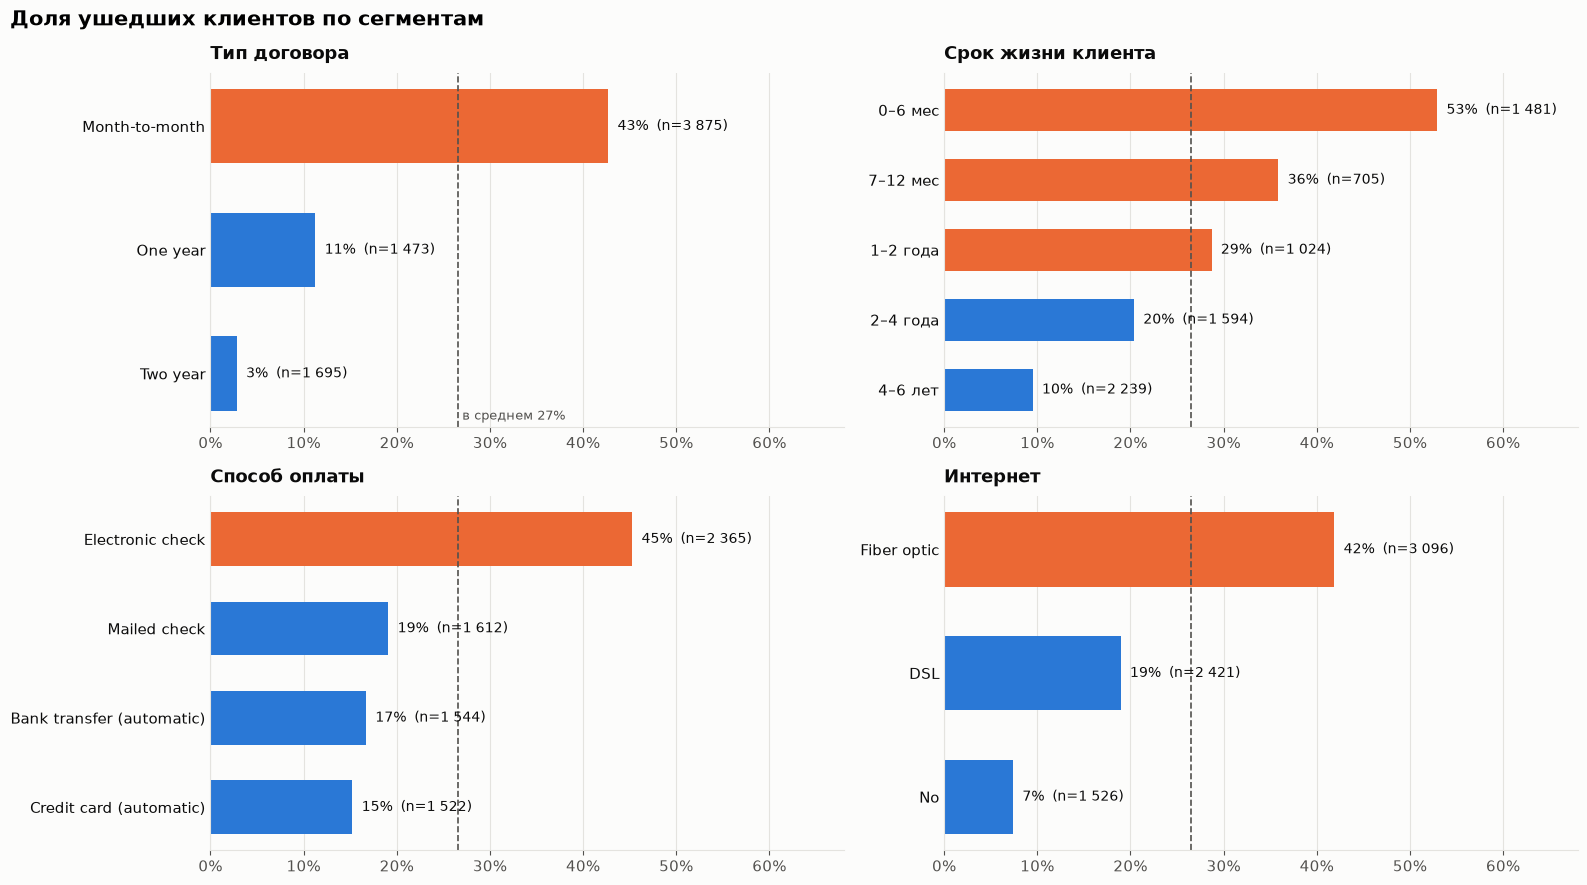

In [5]:
factors = {
    "contract": "Тип договора",
    "tenure_group": "Срок жизни клиента",
    "payment_method": "Способ оплаты",
    "internet_service": "Интернет",
}
avg = df["churn"].mean()
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (col, title) in zip(axes.flat, factors.items()):
    rate = df.groupby(col, observed=True)["churn"].agg(["mean", "size"])
    if col != "tenure_group":
        rate = rate.sort_values("mean", ascending=False)
    bars = ax.barh(rate.index.astype(str), rate["mean"], color=[ORANGE if v > avg else BLUE for v in rate["mean"]], height=0.6)
    ax.invert_yaxis()
    for bar, (v, n) in zip(bars, rate.values):
        ax.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.0%}  (n={int(n):,})".replace(",", " "),
                va="center", color=INK, fontsize=10)
    ax.axvline(avg, color=INK_MUTED, linestyle="--", linewidth=1.2)
    ax.set_title(title)
    ax.set_xlim(0, 0.68)
    ax.xaxis.set_major_formatter(pct)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0, labelcolor=INK)
axes[0, 0].text(avg + 0.005, 0.02, f"в среднем {avg:.0%}", color=INK_MUTED, fontsize=9,
                transform=axes[0, 0].get_xaxis_transform())
fig.suptitle("Доля ушедших клиентов по сегментам", fontsize=15, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_churn_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

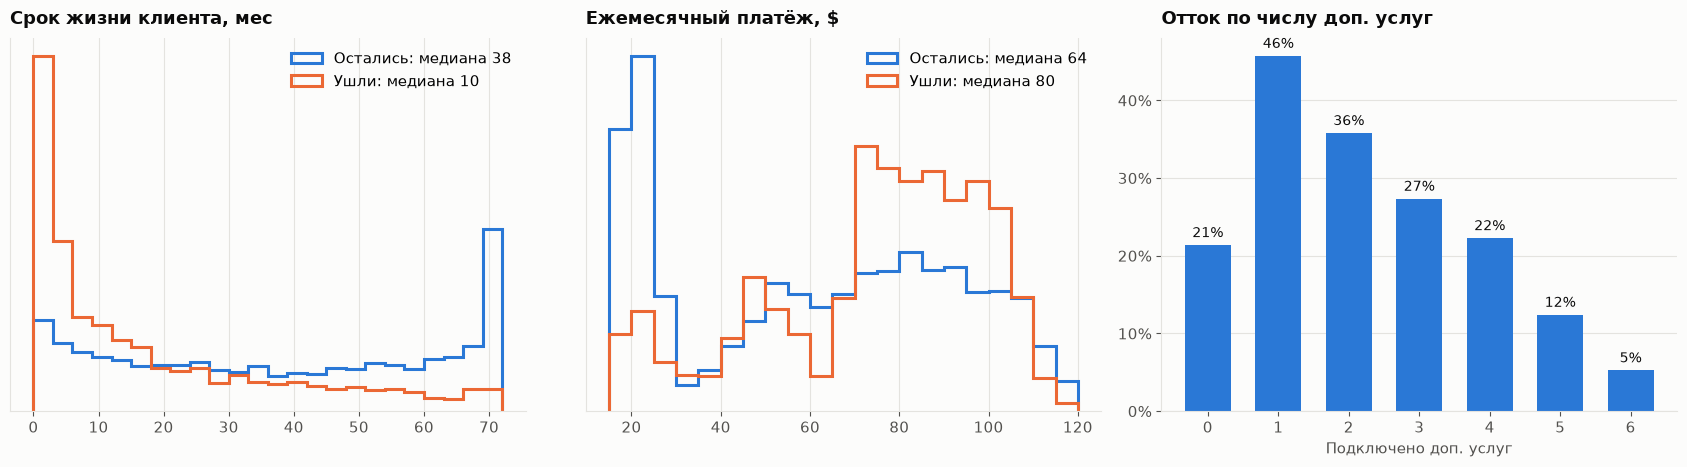

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
labels = {0: "Остались", 1: "Ушли"}
colors = {0: BLUE, 1: ORANGE}

for ax, (col, title, bins) in zip(axes, [
    ("tenure", "Срок жизни клиента, мес", np.arange(0, 75, 3)),
    ("monthly_charges", "Ежемесячный платёж, $", np.arange(15, 125, 5)),
]):
    for k in [0, 1]:
        ax.hist(df.loc[df["churn"] == k, col], bins=bins, density=True, histtype="step", linewidth=2.2,
                color=colors[k], label=f"{labels[k]}: медиана {df.loc[df['churn'] == k, col].median():.0f}")
    ax.set_title(title)
    ax.set_yticks([])
    ax.legend()

svc = df.groupby("services_count")["churn"].mean()
axes[2].bar(svc.index, svc.values, color=BLUE, width=0.65)
for x, v in zip(svc.index, svc.values):
    axes[2].text(x, v + 0.01, f"{v:.0%}", ha="center", color=INK, fontsize=10)
axes[2].set_title("Отток по числу доп. услуг")
axes[2].set_xlabel("Подключено доп. услуг")
axes[2].yaxis.set_major_formatter(pct)
axes[2].grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "02_tenure_charges_services.png", dpi=150, bbox_inches="tight")
plt.show()

**Портрет уходящего клиента**

- **Помесячный договор** — главный фактор: уходят 43% таких клиентов, при годовом договоре — 11%,
  при двухлетнем — 3%.
- **Новички.** Больше половины клиентов уходят в первые полгода. Чем дольше клиент с компанией, тем он лояльнее:
  среди клиентов со стажем 4–6 лет уходят 9,5%.
- **Оптоволокно.** У клиентов с оптоволоконным интернетом отток 42% — вдвое выше, чем с DSL, хотя это более
  дорогая и быстрая услуга. Вероятно, есть проблема с ценой или качеством.
- **Электронный чек.** Отток 45% против 15–19% у остальных способов оплаты. Автоплатёж удерживает клиентов.
- **Платёж.** Ушедшие платили больше (медиана $80 против $64), но провели с компанией меньше времени.
- **Доп. услуги.** Отток падает с ростом их числа: с 46% при одной услуге до 5% при всех шести. Исключение —
  клиенты без доп. услуг (21%): среди них много абонентов без интернета, а они уходят редко.

## Шаг 3. Модели

Делим данные на обучающую (80%) и тестовую (20%) выборки со стратификацией по целевой переменной.
Тестовая выборка используется **один раз**, в конце, для честного сравнения моделей. Гиперпараметры
подбираются кросс-валидацией на обучающей части.

Все модели используют одинаковую предобработку: стандартизация числовых признаков и one-hot кодирование
категорий. Она встроена в `Pipeline`, поэтому на каждом фолде кросс-валидации обучается заново — без утечки
данных из валидации в обучение.

In [7]:
features = ch.NUMERIC + ch.BINARY + ch.CATEGORICAL
X, y = df[features], df[ch.TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=ch.SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=ch.SEED)
print(f"Обучение: {len(X_train)}, тест: {len(X_test)}; доля ушедших — {y_train.mean():.1%} и {y_test.mean():.1%}")

Обучение: 5634, тест: 1409; доля ушедших — 26.5% и 26.5%


### 3.1. Логистическая регрессия — базовая модель

In [8]:
logreg = make_pipeline(ch.make_preprocessor(), LogisticRegression(max_iter=2000))
logreg_search = GridSearchCV(logreg, {"logisticregression__C": [0.01, 0.1, 1, 10]},
                             cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print("Лучший C:", logreg_search.best_params_["logisticregression__C"],
      f"| ROC-AUC на кросс-валидации: {logreg_search.best_score_:.4f}")

Лучший C: 10 | ROC-AUC на кросс-валидации: 0.8464


### 3.2. Градиентный бустинг

`HistGradientBoostingClassifier` из scikit-learn — та же идея, что у LightGBM. Подбираем глубину деревьев,
скорость обучения и число деревьев.

In [9]:
gbm = make_pipeline(ch.make_preprocessor(), HistGradientBoostingClassifier(random_state=ch.SEED))
gbm_grid = {
    "histgradientboostingclassifier__learning_rate": [0.03, 0.1],
    "histgradientboostingclassifier__max_depth": [3, 5],
    "histgradientboostingclassifier__max_iter": [100, 200],
    "histgradientboostingclassifier__min_samples_leaf": [20, 50],
}
gbm_search = GridSearchCV(gbm, gbm_grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print("Лучшие параметры:", {k.split("__")[1]: v for k, v in gbm_search.best_params_.items()})
print(f"ROC-AUC на кросс-валидации: {gbm_search.best_score_:.4f}")

Лучшие параметры: {'learning_rate': 0.03, 'max_depth': 5, 'max_iter': 100, 'min_samples_leaf': 20}
ROC-AUC на кросс-валидации: 0.8489


### 3.3. Нейросеть на PyTorch

Многослойный перцептрон: два скрытых слоя (64 и 32 нейрона), ReLU и Dropout для регуляризации.
- Функция потерь — `BCEWithLogitsLoss` с весом положительного класса, чтобы компенсировать дисбаланс.
- Оптимизатор — Adam с L2-регуляризацией (`weight_decay`).
- **Ранняя остановка:** 15% обучающей выборки отложены для валидации. Обучение останавливается, когда ROC-AUC
  на валидации 15 эпох подряд не растёт, и восстанавливаются веса лучшей эпохи.

In [10]:
try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_AVAILABLE = True
    torch.manual_seed(ch.SEED)
    print("PyTorch", torch.__version__)
except ImportError:
    TORCH_AVAILABLE = False
    print("PyTorch не установлен — раздел с нейросетью будет пропущен (pip install torch)")

PyTorch 2.14.1+cpu


In [11]:
if TORCH_AVAILABLE:
    # Отдельная валидационная выборка для ранней остановки
    X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.15,
                                                  stratify=y_train, random_state=ch.SEED)
    prep = ch.make_preprocessor().fit(X_fit)

    def to_tensor(frame):
        return torch.tensor(np.asarray(prep.transform(frame), dtype=np.float32))

    Xt_fit, Xt_val, Xt_test = to_tensor(X_fit), to_tensor(X_val), to_tensor(X_test)
    yt_fit = torch.tensor(y_fit.values, dtype=torch.float32).unsqueeze(1)

    class ChurnNet(nn.Module):
        def __init__(self, n_features):
            super().__init__()
            self.layers = nn.Sequential(
                nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(0.3),
                nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
                nn.Linear(32, 1),
            )

        def forward(self, x):
            return self.layers(x)  # логиты; вероятность — через sigmoid

    def predict_proba(model, tensor):
        model.eval()
        with torch.no_grad():
            return torch.sigmoid(model(tensor)).squeeze(1).numpy()

    net = ChurnNet(Xt_fit.shape[1])
    pos_weight = torch.tensor([(y_fit == 0).sum() / (y_fit == 1).sum()], dtype=torch.float32)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(Xt_fit, yt_fit), batch_size=128, shuffle=True,
                        generator=torch.Generator().manual_seed(ch.SEED))

    history, best_auc, best_state, patience, wait = [], 0.0, None, 15, 0
    for epoch in range(1, 301):
        net.train()
        epoch_loss = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(net(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(xb)
        val_auc = roc_auc_score(y_val, predict_proba(net, Xt_val))
        history.append({"эпоха": epoch, "loss": epoch_loss / len(Xt_fit), "val_auc": val_auc})
        if val_auc > best_auc:
            best_auc, best_state, wait = val_auc, copy.deepcopy(net.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

    net.load_state_dict(best_state)
    history = pd.DataFrame(history)
    best_epoch = int(history.loc[history["val_auc"].idxmax(), "эпоха"])
    print(f"Остановка на эпохе {epoch}, лучшая — {best_epoch}, ROC-AUC на валидации: {best_auc:.4f}")

Остановка на эпохе 47, лучшая — 32, ROC-AUC на валидации: 0.8433


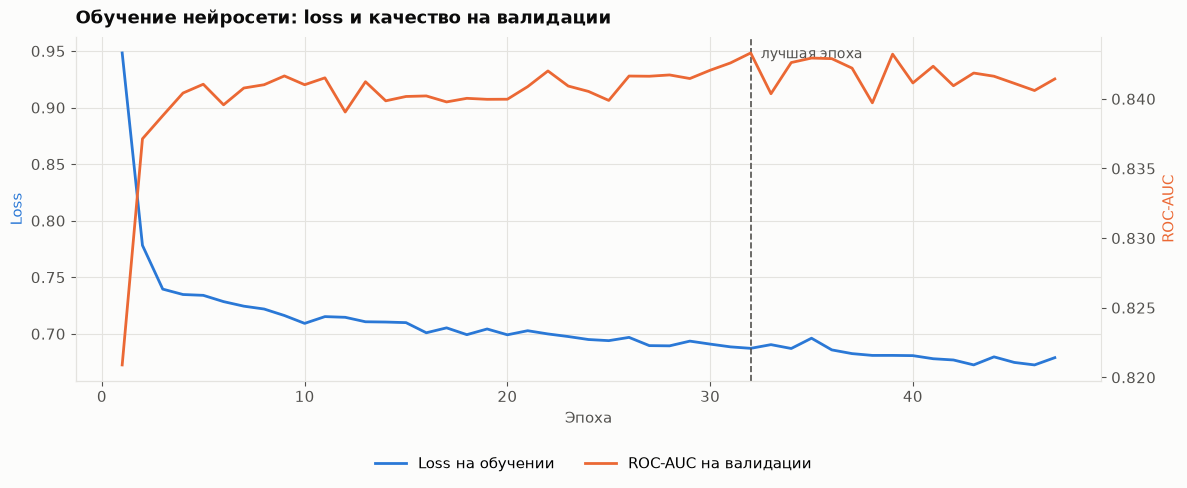

In [12]:
if TORCH_AVAILABLE:
    fig, ax1 = plt.subplots(figsize=(12, 4.5))
    ax1.plot(history["эпоха"], history["loss"], color=BLUE, linewidth=2, label="Loss на обучении")
    ax1.set_xlabel("Эпоха")
    ax1.set_ylabel("Loss", color=BLUE)
    ax2 = ax1.twinx()
    ax2.plot(history["эпоха"], history["val_auc"], color=ORANGE, linewidth=2, label="ROC-AUC на валидации")
    ax2.set_ylabel("ROC-AUC", color=ORANGE)
    ax2.grid(False)
    ax2.spines["right"].set_visible(True)
    ax1.axvline(best_epoch, color=INK_MUTED, linestyle="--", linewidth=1.2)
    ax1.text(best_epoch + 0.5, 0.97, "лучшая эпоха", color=INK_MUTED, va="top", fontsize=10,
             transform=ax1.get_xaxis_transform())
    ax1.set_title("Обучение нейросети: loss и качество на валидации")
    fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncols=2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "03_nn_training.png", dpi=150, bbox_inches="tight")
    plt.show()

### 3.4. Сравнение на тестовой выборке

In [13]:
models = {"Логистическая регрессия": logreg_search.best_estimator_,
          "Градиентный бустинг": gbm_search.best_estimator_}
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
cv_auc = {"Логистическая регрессия": logreg_search.best_score_, "Градиентный бустинг": gbm_search.best_score_}
if TORCH_AVAILABLE:
    test_proba["Нейросеть (PyTorch)"] = predict_proba(net, Xt_test)
    cv_auc["Нейросеть (PyTorch)"] = np.nan  # для нейросети — отдельная валидация, не CV

comparison = pd.DataFrame({
    "ROC-AUC (CV)": cv_auc,
    "ROC-AUC (тест)": {k: roc_auc_score(y_test, p) for k, p in test_proba.items()},
    "PR-AUC (тест)": {k: average_precision_score(y_test, p) for k, p in test_proba.items()},
})
comparison

,ROC-AUC (CV),ROC-AUC (тест),PR-AUC (тест)
Логистическая регрессия,0.846,0.841,0.628
Градиентный бустинг,0.849,0.844,0.654
Нейросеть (PyTorch),NaN,0.844,0.641


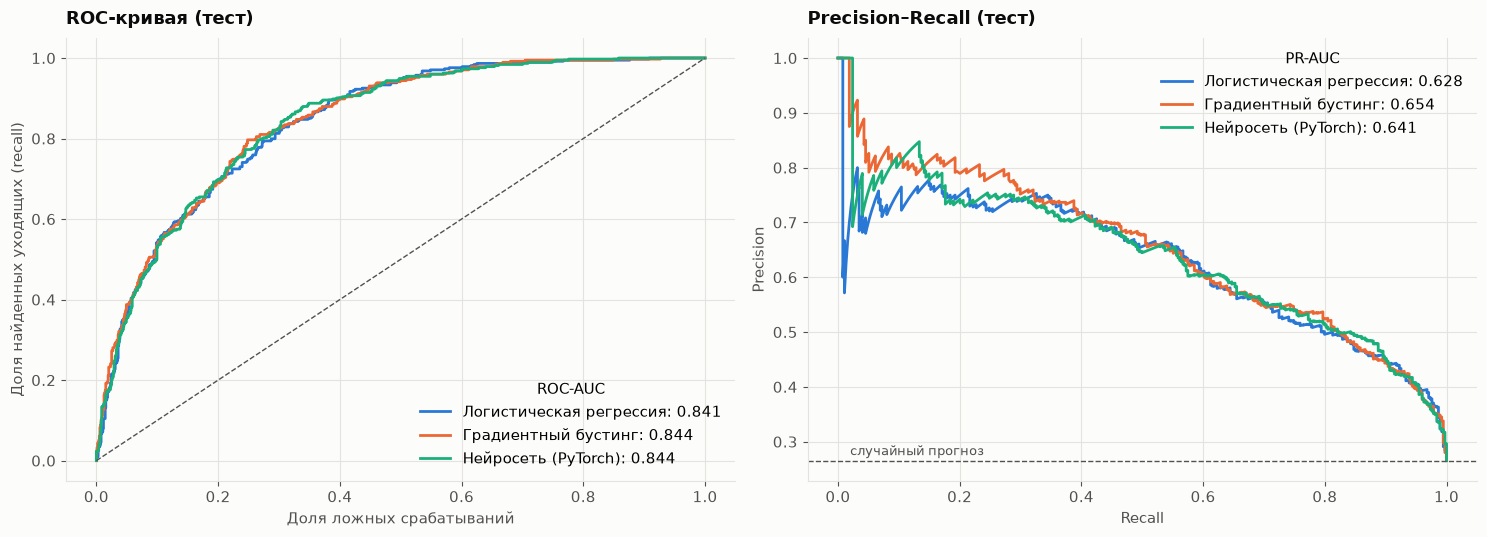

In [14]:
model_colors = {"Логистическая регрессия": BLUE, "Градиентный бустинг": ORANGE, "Нейросеть (PyTorch)": AQUA}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax1.plot(fpr, tpr, color=model_colors[name], linewidth=2, label=f"{name}: {roc_auc_score(y_test, p):.3f}")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax2.plot(rec, prec, color=model_colors[name], linewidth=2, label=f"{name}: {average_precision_score(y_test, p):.3f}")
ax1.plot([0, 1], [0, 1], color=INK_MUTED, linestyle="--", linewidth=1)
ax1.set_title("ROC-кривая (тест)")
ax1.set_xlabel("Доля ложных срабатываний")
ax1.set_ylabel("Доля найденных уходящих (recall)")
ax1.legend(loc="lower right", title="ROC-AUC")
ax2.axhline(y_test.mean(), color=INK_MUTED, linestyle="--", linewidth=1)
ax2.text(0.02, y_test.mean() + 0.01, "случайный прогноз", color=INK_MUTED, fontsize=9)
ax2.set_title("Precision–Recall (тест)")
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.legend(loc="upper right", title="PR-AUC")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Сравнение моделей.** Все модели дают ROC-AUC около **0,84**, и разница между ними в пределах разброса
кросс-валидации (±0,01). Это ожидаемо для табличных данных такого размера: зависимости в основном простые
(договор, срок жизни, способ оплаты), и логистическая регрессия ловит их не хуже сложных моделей.
Нейросеть на 7 тыс. строк не получает преимущества — для табличных данных градиентный бустинг и линейные модели
обычно надёжнее.

Градиентный бустинг чуть лучше по PR-AUC, но разница сопоставима с разбросом между фолдами.

**Выбор модели:** логистическая регрессия. При равном качестве она проще, быстрее, устойчивее
и полностью интерпретируема — это важно, когда маркетингу нужно объяснить, почему клиент попал в список.

## Шаг 4. Что влияет на прогноз

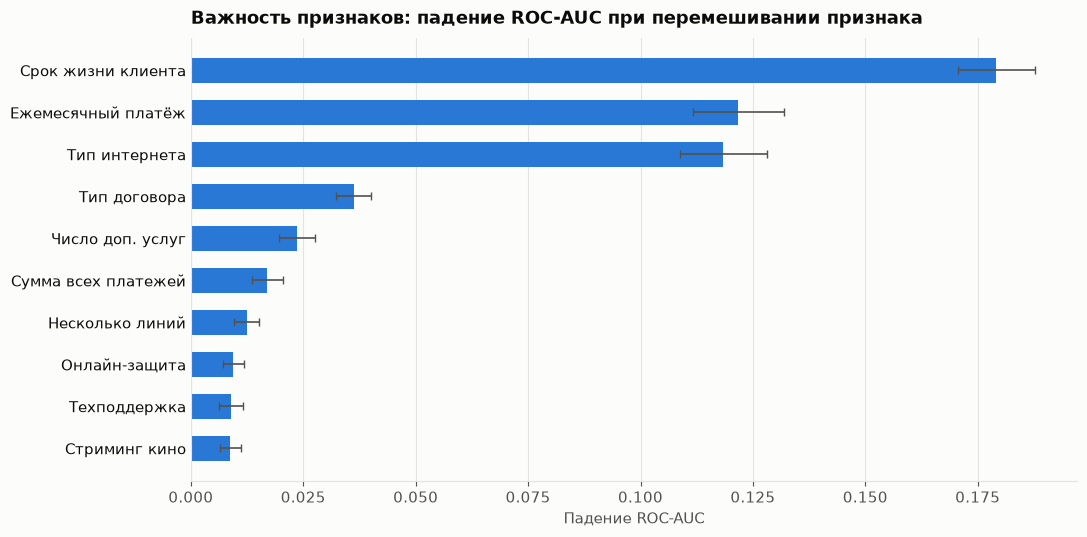

In [15]:
best_model = logreg_search.best_estimator_
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=ch.SEED, n_jobs=-1)
importance = pd.DataFrame({"признак": features, "важность": perm.importances_mean, "std": perm.importances_std})
importance = importance.sort_values("важность", ascending=False).head(10)

names_ru = {
    "contract": "Тип договора", "tenure": "Срок жизни клиента", "internet_service": "Тип интернета",
    "monthly_charges": "Ежемесячный платёж", "total_charges": "Сумма всех платежей",
    "payment_method": "Способ оплаты", "tech_support": "Техподдержка", "online_security": "Онлайн-защита",
    "paperless_billing": "Электронные счета", "streaming_tv": "Стриминг ТВ", "streaming_movies": "Стриминг кино",
    "senior_citizen": "Пенсионер", "services_count": "Число доп. услуг", "multiple_lines": "Несколько линий",
    "dependents": "Есть иждивенцы", "partner": "Есть партнёр", "phone_service": "Телефония",
    "online_backup": "Онлайн-бэкап", "device_protection": "Защита устройства", "gender": "Пол",
}
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(importance["признак"].map(names_ru), importance["важность"], xerr=importance["std"], color=BLUE, height=0.6,
        error_kw={"ecolor": INK_MUTED, "elinewidth": 1.2, "capsize": 3})
ax.invert_yaxis()
ax.set_title("Важность признаков: падение ROC-AUC при перемешивании признака")
ax.set_xlabel("Падение ROC-AUC")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**Интерпретация.** Важность считаем перестановочным методом: перемешиваем один признак на тестовой выборке
и смотрим, насколько падает ROC-AUC. Метод не зависит от типа модели и учитывает признак целиком,
а не отдельные one-hot столбцы.

- **Срок жизни клиента** — самый сильный признак: новички уходят в разы чаще.
- **Ежемесячный платёж** и **тип интернета** идут следом и связаны между собой: оптоволокно — самый дорогой
  тариф и самый высокий отток.
- **Тип договора** в модели важен меньше, чем в анализе: он сильно связан со сроком жизни (длинные договоры —
  у старых клиентов), и часть его информации модель уже получает из `tenure`.
- Пол, наличие партнёра и телефония на прогноз почти не влияют.

Модель опирается на те же понятные бизнес-факторы, что видны в исследовательском анализе, а не на случайные зависимости.

## Шаг 5. Кому предлагать удержание

Модель выдаёт вероятность ухода. Порог 0,5 по умолчанию ничем не обоснован: нужно выбрать порог,
при котором **кампания удержания приносит максимум прибыли**.

**Допущения** (их легко поменять под реальные цифры компании):
- клиенту из группы риска предлагаем скидку, которая стоит компании **$60** (например, 20% на 3 месяца);
- скидка удерживает **30%** тех, кто собирался уйти;
- удержанный клиент приносит ещё **12 месяцев** своего текущего платежа;
- скидку получают и те, кто не ушёл бы, — для них это чистые расходы.

Оптимальный порог: 0.25 — в кампанию 610 из 1409 клиентов  прибыль $45 854
Порог 0.5: прибыль $39 910
Скидка всем клиентам: прибыль $13 434


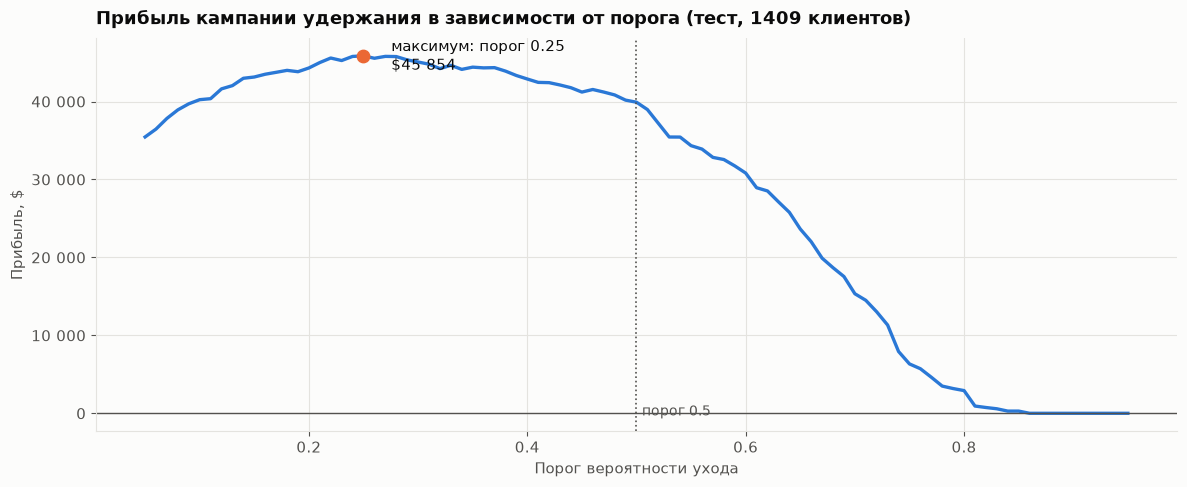

In [16]:
OFFER_COST, SUCCESS_RATE, HORIZON_MONTHS = 60, 0.30, 12
value = X_test["monthly_charges"].values * HORIZON_MONTHS
proba = test_proba["Логистическая регрессия"]

curve = ch.profit_curve(y_test.values, proba, value, OFFER_COST, SUCCESS_RATE)
best = curve.loc[curve["прибыль"].idxmax()]
at_05 = curve.loc[(curve["порог"] - 0.5).abs().idxmin()]
all_in = (SUCCESS_RATE * value * y_test.values).sum() - OFFER_COST * len(y_test)

print(f"Оптимальный порог: {best['порог']:.2f} — в кампанию {int(best['клиентов в кампании'])} из {len(y_test)} клиентов, "
      f"прибыль ${best['прибыль']:,.0f}".replace(",", " "))
print(f"Порог 0.5: прибыль ${at_05['прибыль']:,.0f}".replace(",", " "))
print(f"Скидка всем клиентам: прибыль ${all_in:,.0f}".replace(",", " "))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(curve["порог"], curve["прибыль"], color=BLUE, linewidth=2.4)
ax.axhline(0, color=INK_MUTED, linewidth=1)
ax.scatter([best["порог"]], [best["прибыль"]], color=ORANGE, s=80, zorder=3)
ax.annotate(f"максимум: порог {best['порог']:.2f}\n${best['прибыль']:,.0f}".replace(",", " "),
            (best["порог"], best["прибыль"]), xytext=(20, -10), textcoords="offset points", color=INK)
ax.axvline(0.5, color=INK_MUTED, linestyle=":", linewidth=1.2)
ax.text(0.505, 0.04, "порог 0.5", color=INK_MUTED, fontsize=10, transform=ax.get_xaxis_transform())
ax.set_title(f"Прибыль кампании удержания в зависимости от порога (тест, {len(y_test)} клиентов)")
ax.set_xlabel("Порог вероятности ухода")
ax.set_ylabel("Прибыль, $")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
fig.tight_layout()
fig.savefig(FIG_DIR / "06_profit_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Насколько вывод зависит от допущений: оптимальный порог и прибыль при разной эффективности и цене скидки
grid = []
for rate in [0.2, 0.3, 0.4]:
    for cost in [30, 60, 100]:
        c = ch.profit_curve(y_test.values, proba, value, cost, rate)
        b = c.loc[c["прибыль"].idxmax()]
        grid.append({"удерживает": f"{rate:.0%}", "цена скидки": f"${cost}", "порог": b["порог"],
                     "в кампании": int(b["клиентов в кампании"]), "прибыль": round(b["прибыль"])})
pd.DataFrame(grid).pivot(index="удерживает", columns="цена скидки", values=["порог", "прибыль"])

порог                прибыль                      
цена скидки  $100   $30   $60       $100        $30        $60
удерживает                                                    
20%         0.590 0.220 0.480  8,080.000 36,865.000 20,289.000
30%         0.500 0.080 0.250 27,230.000 66,737.000 45,854.000
40%         0.280 0.050 0.220 49,800.000 98,467.000 73,729.000

**Результат.** При базовых допущениях оптимальный порог — **0,25**: скидку получают 43% клиентов, и кампания
приносит около **$46 тыс.** на 1 409 клиентов тестовой выборки. Это на 15% больше, чем при стандартном пороге 0,5
(~$40 тыс.), и в 3,4 раза больше, чем при скидке всем подряд (~$13 тыс.).

Оптимальный порог сильно зависит от экономики кампании: при дешёвой скидке выгодно охватывать почти всех
с заметным риском (порог 0,05–0,2), при дорогой и слабо работающей — только самых рискованных (порог до 0,6).
Поэтому порог — это бизнес-решение, которое пересчитывается по реальным цифрам, а не константа 0,5.

## Выводы и рекомендации

**Кто уходит.** Каждый четвёртый клиент ушёл, и они уносят почти треть ежемесячной выручки. Типичный уходящий клиент —
новичок (первые полгода) на помесячном договоре с оптоволокном, который платит электронным чеком и не подключил
техподдержку или защиту.

**Модель.** Логистическая регрессия, градиентный бустинг и нейросеть на PyTorch показали почти одинаковое качество
(ROC-AUC ≈ 0,84). Бустинг чуть лучше по PR-AUC, но разница в пределах шума. Выбрана логистическая регрессия:
при равной точности она проще и объяснима. Сложная модель здесь не даёт выигрыша — это нормальный и полезный результат.

**Экономика.** Порог, подобранный по прибыли, даёт на 15% больше, чем стандартный 0,5, и в 3,4 раза больше,
чем скидка всем клиентам.

**Рекомендации**
1. **Переводить клиентов на длинные договоры.** Отток на годовом договоре в 4 раза ниже, на двухлетнем — в 15 раз.
   Скидка за переход с помесячного договора — главный рычаг удержания.
2. **Работать с новичками в первые полгода:** онбординг, проверка качества связи, бонус за первые месяцы.
3. **Разобраться с оптоволокном.** Высокий отток при дорогой услуге указывает на проблему с ценой или качеством,
   это стоит проверить отдельно (жалобы, скорость, цены конкурентов).
4. **Переводить на автоплатёж** клиентов, которые платят электронным чеком.
5. **Запускать кампанию удержания по модели**, выбирая порог по прибыли, а не по умолчанию 0,5,
   и пересчитывать его, когда будут известны реальная цена скидки и её эффективность (через A/B-тест кампании).

**Ограничения.** Данные — снимок за один месяц без истории поведения (звонки в поддержку, изменение трат).
С такими признаками модель можно было бы заметно улучшить. Эффективность скидки взята как допущение;
её нужно измерить в A/B-тесте перед масштабированием.